# Task 1: Inflation betas of the major asset classes

```text
1. Monthly total returns (dividends reinvested, Yahoo adjusted prices):
     US equities     SPY  (S&P 500)
     Treasuries      IEF  (7-10y nominal Treasuries)
     Commodities TR  DBC  (broad commodity index; NAV includes T-bill collateral income)
     Gold            GLD
     REITs           VNQ
   Common sample starts when the youngest ETF (DBC, Feb 2006) starts -> ~20 years.
2. Monthly inflation = % change of CPI (CPIAUCSL, seasonally adjusted, FRED).
3. Regress each asset's monthly return on inflation, Newey-West standard errors:
     r_t = a + beta * infl_t + e_t
   beta = 1 -> nominal return moves one-for-one with inflation (real return protected)
   beta < 0 -> asset loses value when inflation rises
   Also reports the real (CPI-deflated) return of each asset. Rank by beta.
4. Stretch: split inflation into expected + unexpected.
     expected   = real-time AR(1) forecast, estimated on the previous ROLL_AR months only
                  (no look-ahead)
     unexpected = actual - expected
   Re-run the regressions on the unexpected part.

Data (free, no API key): Yahoo Finance via yfinance, FRED CSV download.
Run in VS Code / Jupyter with the team environment. Needs pandas, numpy, matplotlib,
statsmodels, yfinance (`uv add statsmodels yfinance` if not yet in pyproject.toml).
```

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import yfinance as yf

BASE = Path.cwd()
OUT = BASE / "data"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved in: {OUT}")

ASSETS = {"SPY": "US equities", "IEF": "Treasuries 7-10y", "DBC": "Commodities TR",
          "GLD": "Gold", "VNQ": "REITs"}
NW_LAGS = 6      # Newey-West lags
ROLL_AR = 120    # months of history used for each real-time AR(1) inflation forecast

Outputs will be saved in: /Users/macc/Documents/asset-allocation-26-27/Assignment4/Task1/data


## 1. Download data

In [2]:
def fred(series_id):
    """Monthly FRED series via the public CSV endpoint (no API key needed)."""
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    s = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    s.index = s.index.to_period("M").to_timestamp()
    return s.rename(series_id)


def yahoo_monthly_returns(tickers):
    """Monthly total returns (decimals) from dividend-adjusted closing prices."""
    px = yf.download(list(tickers), start="1990-01-01", auto_adjust=True,
                     progress=False)["Close"]
    px = px.resample("ME").last()
    px.index = px.index.to_period("M").to_timestamp()
    return px.pct_change(fill_method=None)


rets = yahoo_monthly_returns(ASSETS).rename(columns=ASSETS)
infl_all = fred("CPIAUCSL").pct_change().rename("infl")   # full history, used for AR(1)

df = rets.join(infl_all, how="inner").dropna()            # common sample
df.to_csv(OUT / "data_monthly.csv")
print(f"Sample: {df.index[0]:%Y-%m} to {df.index[-1]:%Y-%m}, {len(df)} months")

Sample: 2006-03 to 2026-09, 245 months


## 2. Expected vs unexpected inflation (stretch)

In [3]:
def realtime_ar1_forecast(infl, window=ROLL_AR):
    """Forecast of infl_t from an AR(1) fitted only on months t-window .. t-1."""
    x = infl.dropna()
    fc = pd.Series(np.nan, index=x.index)
    for i in range(window + 1, len(x)):
        hist = x.iloc[i - window - 1:i]
        slope, const = np.polyfit(hist.shift(1).iloc[1:], hist.iloc[1:], 1)
        fc.iloc[i] = const + slope * x.iloc[i - 1]
    return fc


df["infl_expected"] = realtime_ar1_forecast(infl_all).reindex(df.index)
df["infl_surprise"] = df["infl"] - df["infl_expected"]

## 3. Inflation betas

In [4]:
def ols(y, x):
    """OLS of y on a constant and x, Newey-West standard errors."""
    m = sm.OLS(y, sm.add_constant(x), missing="drop").fit(
        cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    return m.params.iloc[1], m.bse.iloc[1], m.tvalues.iloc[1], m.pvalues.iloc[1], m.rsquared


rows = {}
for a in ASSETS.values():
    b, se, t, p, r2 = ols(df[a], df["infl"])
    bs, ses, ts, _, r2s = ols(df[a], df["infl_surprise"])
    real = (1 + df[a]) / (1 + df["infl"]) - 1
    rows[a] = {
        "beta": b, "se (NW)": se, "t": t, "p": p, "R2": r2,
        "beta surprise": bs, "se surprise": ses, "t surprise": ts, "R2 surprise": r2s,
        "real return (ann.)": (1 + real).prod() ** (12 / len(real)) - 1,
        "real vol (ann.)": real.std() * np.sqrt(12),
    }

res = pd.DataFrame(rows).T.sort_values("beta", ascending=False)
res.insert(0, "rank", range(1, len(res) + 1))
res.to_csv(OUT / "inflation_betas.csv")

report = (
    f"=== Inflation betas, {df.index[0]:%Y-%m} to {df.index[-1]:%Y-%m}, N = {len(df)} ===\n"
    f"Monthly return regressed on monthly CPI inflation; beta = 1 means full hedge.\n"
    f"'surprise' = inflation minus real-time AR(1) forecast ({ROLL_AR}-month window).\n\n"
    f"{res.round(3).to_string()}\n\n"
    f"Inflation: mean {df['infl'].mean() * 12:.2%} p.a., monthly std {df['infl'].std():.2%}; "
    f"surprise monthly std {df['infl_surprise'].std():.2%}"
)
print(report)
(OUT / "results.txt").write_text(report);

=== Inflation betas, 2006-03 to 2026-09, N = 245 ===
Monthly return regressed on monthly CPI inflation; beta = 1 means full hedge.
'surprise' = inflation minus real-time AR(1) forecast (120-month window).

                  rank   beta  se (NW)      t      p     R2  beta surprise  se surprise  t surprise  R2 surprise  real return (ann.)  real vol (ann.)
Commodities TR       1  7.162    1.176  6.091  0.000  0.171          8.285        1.651       5.017        0.178               0.001            0.184
US equities          2  1.003    1.295  0.775  0.438  0.005          1.386        1.480       0.936        0.008               0.082            0.151
REITs                3  0.428    2.594  0.165  0.869  0.000          1.226        3.229       0.380        0.003               0.033            0.219
Gold                 4 -0.296    0.947 -0.313  0.754  0.000          0.574        1.121       0.512        0.001               0.066            0.175
Treasuries 7-10y     5 -1.907    0.413 -4.62

## 4. Charts

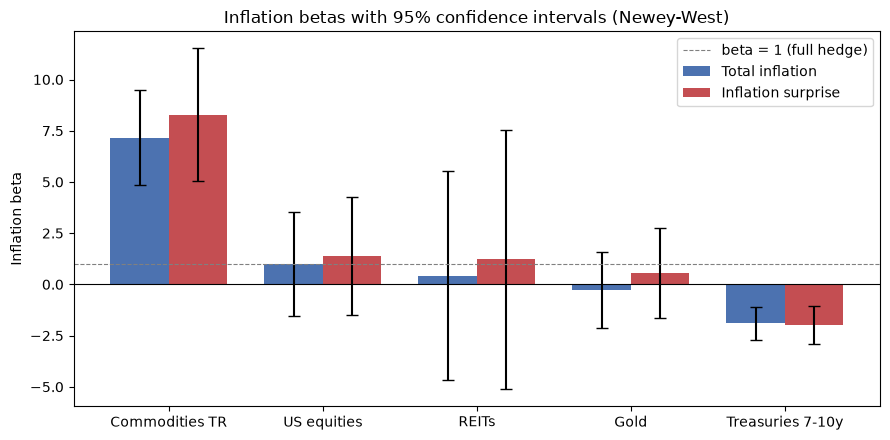

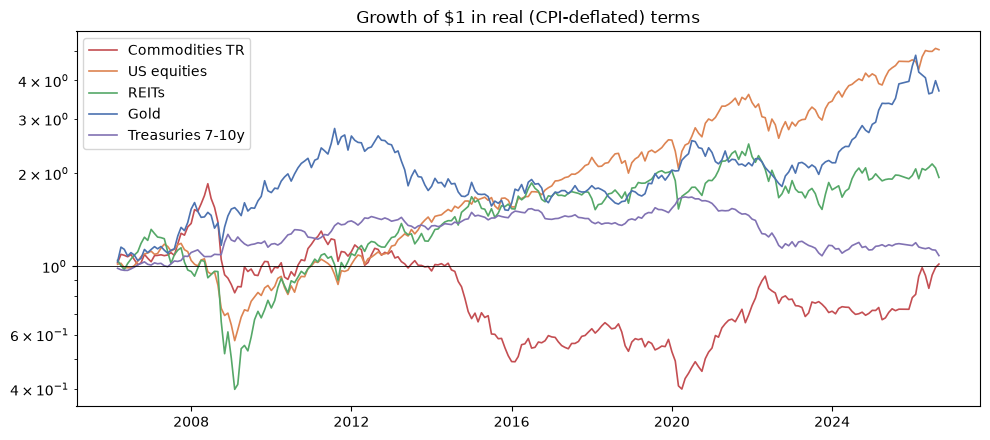


Done. Outputs in /Users/macc/Documents/asset-allocation-26-27/Assignment4/Task1/data


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(res))
w = 0.38
ax.bar(x - w / 2, res["beta"], w, yerr=1.96 * res["se (NW)"], capsize=4,
       color="#4c72b0", label="Total inflation")
ax.bar(x + w / 2, res["beta surprise"], w, yerr=1.96 * res["se surprise"], capsize=4,
       color="#c44e52", label="Inflation surprise")
ax.axhline(0, color="black", lw=0.8)
ax.axhline(1, color="grey", lw=0.8, ls="--", label="beta = 1 (full hedge)")
ax.set_xticks(x)
ax.set_xticklabels(res.index)
ax.set_ylabel("Inflation beta")
ax.set_title("Inflation betas with 95% confidence intervals (Newey-West)")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "inflation_betas.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
for a, c in zip(res.index, ["#c44e52", "#dd8452", "#55a868", "#4c72b0", "#8172b3"]):
    real = (1 + df[a]) / (1 + df["infl"]) - 1
    ax.plot(df.index, (1 + real).cumprod(), label=a, color=c, lw=1.2)
ax.axhline(1, color="black", lw=0.6)
ax.set_yscale("log")
ax.set_title("Growth of $1 in real (CPI-deflated) terms")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "real_wealth.png", dpi=150)
plt.show()

print(f"\nDone. Outputs in {OUT}")